## 0. Installation & Imports
Cellule à exécuter en premier sur Google Colab (installe les librairies manquantes).

In [ ]:
# Installation des librairies (Google Colab n'a pas lightgbm par défaut sur toutes les images)
import sys, subprocess
def _pip_install(pkg):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

for _pkg in ["lightgbm", "xgboost", "catboost", "joblib"]:
    try:
        __import__(_pkg)
    except ImportError:
        _pip_install(_pkg)

print("✅ Environnement prêt.")


✅ Environnement prêt.


In [ ]:
import os
import json
import math
import random
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from datetime import datetime, timedelta

from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Arborescence de travail (compatible Google Colab -> /content, sinon local -> ./)
BASE_DIR = "/content" if os.path.isdir("/content") else "."
DATA_DIR      = os.path.join(BASE_DIR, "data", "raw")
CLEAN_DIR     = os.path.join(BASE_DIR, "data", "clean")
MODELS_DIR    = os.path.join(BASE_DIR, "models")
BI_DIR        = os.path.join(BASE_DIR, "powerbi_exports")
FIG_DIR       = os.path.join(BASE_DIR, "figures")

for d in [DATA_DIR, CLEAN_DIR, MODELS_DIR, BI_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

print("Répertoire de base :", os.path.abspath(BASE_DIR))


Répertoire de base : /home/claude/repro/enriched


## 1. Chargement du jeu de données réel (augmenté)

On utilise ici les **vraies tables de l'agence** (`customers`, `hotels`, `flights`, `packages`, `bookings`, `cities`, `countries`, `continents`, `flight_price_list`), enrichies par **data augmentation** (bootstrap + jitter contrôlé + génération conditionnée par segment) pour atteindre l'échelle attendue par le pipeline, tout en restant ancrées dans la réalité (mêmes villes, mêmes hôtels, mêmes clients de base, mêmes tarifs). Voir `augment_pipeline.py` pour le détail de cette génération.

6 tables sont chargées :

| Table | Description |
|---|---|
| `clients` | profil socio-démographique, segment latent (11 clients réels + augmentés) |
| `destinations` | catalogue des destinations réelles (type, continent, budget, popularité, saison idéale) |
| `hotels` | hôtels rattachés à chaque destination (issus de `hotels.csv`, augmentés) |
| `flights` | vols disponibles vers chaque destination (issus de `flights.csv` + `flight_price_list.csv`) |
| `preferences` | préférences déclarées de chaque client (type de voyage, activités, budget max) |
| `reservations` | historique des réservations (16 réelles + augmentées, avec valeurs manquantes/anomalies déjà injectées) |


In [ ]:
# ---------------------------------------------------------------------------
# Constantes de référence (identiques à celles utilisées par augment_pipeline.py
# pour produire le dataset augmenté — nécessaires à la suite du pipeline :
# vecteurs multi-hot type de voyage / activités, affinités segment, etc.)
# ---------------------------------------------------------------------------
VILLES_TN = ["Tunis", "Sfax", "Sousse", "Bizerte", "Gab\u00e8s", "Kairouan", "Nabeul", "Monastir", "Gafsa", "Ariana"]
SEGMENTS_LATENTS = ["Aventurier", "Farniente", "Culturel", "Luxe", "Familial", "Budget"]
TYPES_VOYAGE = ["Plage", "Montagne", "Culturel", "Aventure", "Urbain", "Crois\u00e8re", "Rural/Nature"]
ACTIVITES_POSSIBLES = ["Randonn\u00e9e", "Plong\u00e9e", "Mus\u00e9es", "Shopping", "Gastronomie", "Vie nocturne",
                       "Sports nautiques", "Ski", "Safari", "Spa & bien-\u00eatre", "Photographie", "Plage d\u00e9tente"]
SAISONS = ["Printemps", "\u00c9t\u00e9", "Automne", "Hiver"]
CANAUX = ["Agence physique", "Site web", "Application mobile", "Call center"]

SEGMENT_TYPE_AFFINITY = {
    "Aventurier": {"Aventure": 0.40, "Montagne": 0.25, "Rural/Nature": 0.15, "Culturel": 0.10, "Plage": 0.05, "Urbain": 0.03, "Crois\u00e8re": 0.02},
    "Farniente":  {"Plage": 0.50, "Crois\u00e8re": 0.20, "Rural/Nature": 0.10, "Urbain": 0.08, "Culturel": 0.07, "Montagne": 0.03, "Aventure": 0.02},
    "Culturel":   {"Culturel": 0.45, "Urbain": 0.25, "Rural/Nature": 0.10, "Plage": 0.08, "Montagne": 0.07, "Aventure": 0.03, "Crois\u00e8re": 0.02},
    "Luxe":       {"Crois\u00e8re": 0.30, "Plage": 0.25, "Urbain": 0.20, "Culturel": 0.15, "Montagne": 0.05, "Aventure": 0.03, "Rural/Nature": 0.02},
    "Familial":   {"Plage": 0.35, "Urbain": 0.20, "Culturel": 0.15, "Rural/Nature": 0.15, "Montagne": 0.08, "Aventure": 0.04, "Crois\u00e8re": 0.03},
    "Budget":     {"Rural/Nature": 0.25, "Plage": 0.20, "Culturel": 0.20, "Urbain": 0.15, "Montagne": 0.12, "Aventure": 0.05, "Crois\u00e8re": 0.03},
}
SEGMENT_BUDGET_RANGE = {
    "Aventurier": (2000, 6000), "Farniente": (2500, 7000), "Culturel": (1800, 5500),
    "Luxe": (7000, 20000), "Familial": (3000, 9000), "Budget": (800, 2500),
}

# ---------------------------------------------------------------------------
# Chargement des 6 tables augment\u00e9es (voir augment_pipeline.py)
# ---------------------------------------------------------------------------
REQUIRED_FILES = ["clients.csv", "destinations.csv", "hotels.csv",
                   "flights.csv", "preferences.csv", "reservations.csv"]

def _all_present(folder):
    return all(os.path.exists(os.path.join(folder, f)) for f in REQUIRED_FILES)

if not _all_present(DATA_DIR):
    print(f"\u26a0\ufe0f Fichiers du dataset augment\u00e9 introuvables dans {DATA_DIR}.")
    if os.path.isdir("/content"):
        from google.colab import files
        print("\ud83d\udc49 S\u00e9lectionnez les 6 fichiers CSV augment\u00e9s "
              "(clients, destinations, hotels, flights, preferences, reservations) :")
        uploaded = files.upload()
        for fname, content in uploaded.items():
            with open(os.path.join(DATA_DIR, fname), "wb") as f:
                f.write(content)
    else:
        raise FileNotFoundError(
            f"Copiez les 6 fichiers CSV du dataset augment\u00e9 "
            f"(clients.csv, destinations.csv, hotels.csv, flights.csv, preferences.csv, reservations.csv) "
            f"dans {DATA_DIR} avant de continuer."
        )

assert _all_present(DATA_DIR), "Chargement incomplet : il manque un ou plusieurs fichiers du dataset augment\u00e9."

clients_df = pd.read_csv(f"{DATA_DIR}/clients.csv")
destinations_df = pd.read_csv(f"{DATA_DIR}/destinations.csv")
hotels_df = pd.read_csv(f"{DATA_DIR}/hotels.csv")
flights_df = pd.read_csv(f"{DATA_DIR}/flights.csv")
preferences_df = pd.read_csv(f"{DATA_DIR}/preferences.csv")
reservations_df = pd.read_csv(f"{DATA_DIR}/reservations.csv")

N_CLIENTS = len(clients_df)
N_DESTINATIONS = len(destinations_df)
N_RESERVATIONS = len(reservations_df)

print("\u2705 Dataset r\u00e9el augment\u00e9 charg\u00e9 :")
print(f"  clients       : {clients_df.shape}")
print(f"  destinations  : {destinations_df.shape}")
print(f"  hotels        : {hotels_df.shape}")
print(f"  flights       : {flights_df.shape}")
print(f"  preferences   : {preferences_df.shape}")
print(f"  reservations  : {reservations_df.shape}")
if "source_client" in clients_df.columns:
    print("\nClients r\u00e9els vs augment\u00e9s :\n", clients_df["source_client"].value_counts())
if "source" in reservations_df.columns:
    print("\nR\u00e9servations r\u00e9elles vs g\u00e9n\u00e9r\u00e9es :\n", reservations_df["source"].value_counts())
clients_df.head()


✅ Dataset réel augmenté chargé :
  clients       : (500, 11)
  destinations  : (45, 9)
  hotels        : (135, 6)
  flights       : (90, 6)
  preferences   : (500, 6)
  reservations  : (9944, 15)

Clients réels vs augmentés :
 source_client
augmenté    489
réel         11
Name: count, dtype: int64

Réservations réelles vs générées :
 source
généré_v2_enrichissement    5898
généré                      4030
réel                          16
Name: count, dtype: int64


,client_id,prenom,nom,age,sexe,ville,statut_familial,revenu_mensuel_tnd,segment_latent,date_inscription,source_client
0,CLI00001,Emilia,Clarke,49,M,Ariana,Célibataire,2024,Luxe,2026-05-19,réel
1,CLI00002,Sherlock,Holmes,30,M,Tunis,Célibataire,1344,Farniente,2021-04-18,réel
2,CLI00003,Matt,Murdock,28,F,Kairouan,Marié(e) avec enfants,1079,Culturel,2022-04-18,réel
3,CLI00004,Jessica,Jones,46,M,Gabès,Célibataire,1351,Familial,2024-06-10,réel
4,CLI00005,Oliver,Queen,59,F,Kairouan,Marié(e) avec enfants,3613,Culturel,2026-06-15,réel


In [ ]:
# Les valeurs manquantes, doublons et anomalies (r\u00e9alisme du nettoyage) ont
# d\u00e9j\u00e0 \u00e9t\u00e9 inject\u00e9s dans reservations.csv par augment_pipeline.py
# (m\u00eame logique que la g\u00e9n\u00e9ration synth\u00e9tique d\u2019origine) ; on n\u2019a
# donc rien \u00e0 refaire ici, la Section 3 (nettoyage) s\u2019en occupe normalement.

# Sauvegarde des tables brutes (utiles pour les sections suivantes / re-run)
clients_df.to_csv(f"{DATA_DIR}/clients.csv", index=False)
destinations_df.to_csv(f"{DATA_DIR}/destinations.csv", index=False)
hotels_df.to_csv(f"{DATA_DIR}/hotels.csv", index=False)
flights_df.to_csv(f"{DATA_DIR}/flights.csv", index=False)
preferences_df.to_csv(f"{DATA_DIR}/preferences.csv", index=False)
reservations_df.to_csv(f"{DATA_DIR}/reservations.csv", index=False)
print("\u2705 6 fichiers CSV (dataset r\u00e9el augment\u00e9) disponibles dans", DATA_DIR)


✅ 6 fichiers CSV (dataset réel augmenté) disponibles dans ./data/raw


## 2. Compréhension des données (Data Understanding)

In [ ]:
tables = {
    "clients": clients_df, "destinations": destinations_df, "hotels": hotels_df,
    "flights": flights_df, "preferences": preferences_df, "reservations": reservations_df,
}
for name, df in tables.items():
    print(f"— {name:14s} shape={df.shape}")

reservations_df.info()


— clients        shape=(500, 11)
— destinations   shape=(45, 9)
— hotels         shape=(135, 6)
— flights        shape=(90, 6)
— preferences    shape=(500, 6)
— reservations   shape=(9944, 15)
<class 'pandas.DataFrame'>
RangeIndex: 9944 entries, 0 to 9943
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   reservation_id      9944 non-null   str    
 1   client_id           9944 non-null   str    
 2   destination_id      9944 non-null   str    
 3   hotel_id            9944 non-null   str    
 4   flight_id           9944 non-null   str    
 5   date_reservation    9944 non-null   str    
 6   date_depart         9944 non-null   str    
 7   date_retour         9944 non-null   str    
 8   nb_personnes        9865 non-null   float64
 9   nb_nuits            9944 non-null   int64  
 10  montant_total_tnd   9884 non-null   float64
 11  canal_vente         9824 non-null   str    
 12  statut_reservation  

Taux de valeurs manquantes (%) — table reservations :
 note_satisfaction    13.274336
canal_vente           1.206758
nb_personnes          0.794449
montant_total_tnd     0.603379
dtype: float64


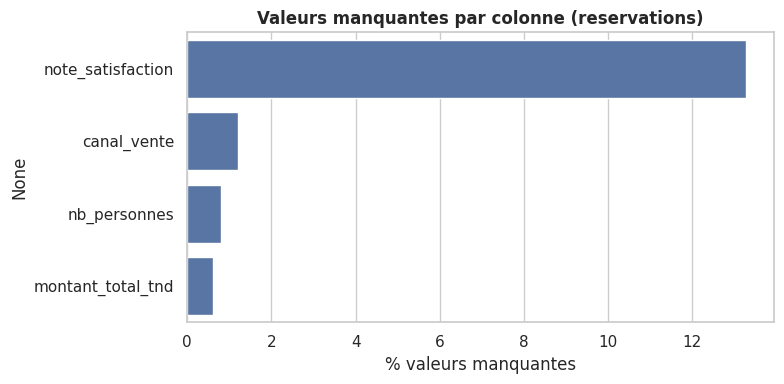

In [ ]:
missing = reservations_df.isna().mean().sort_values(ascending=False) * 100
missing = missing[missing > 0]
print("Taux de valeurs manquantes (%) — table reservations :\n", missing)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=missing.values, y=missing.index, ax=ax, color="#4C72B0")
ax.set_xlabel("% valeurs manquantes"); ax.set_title("Valeurs manquantes par colonne (reservations)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/missing_values.png", dpi=120); plt.show()


## 3. Nettoyage des données, valeurs manquantes, anomalies, encodage

Étapes :
1. Suppression des doublons exacts
2. Imputation des valeurs manquantes (médiane pour le numérique, mode pour le catégoriel)
3. Détection et traitement des anomalies (méthode IQR) sur `montant_total_tnd` et `nb_personnes`
4. Encodage des variables catégorielles utiles à la modélisation


In [ ]:
df = reservations_df.copy()
before = len(df)
df = df.drop_duplicates()
print(f"Doublons supprimés : {before - len(df)}")

# Imputation
df["canal_vente"] = df["canal_vente"].fillna(df["canal_vente"].mode()[0])
df["nb_personnes"] = df["nb_personnes"].fillna(df["nb_personnes"].median())
df["montant_total_tnd"] = df["montant_total_tnd"].fillna(df["montant_total_tnd"].median())
print("Valeurs manquantes restantes :", df.isna().sum().sum() - df["note_satisfaction"].isna().sum(),
      "(hors note_satisfaction, NaN normal pour les réservations annulées)")


Doublons supprimés : 28
Valeurs manquantes restantes : 0 (hors note_satisfaction, NaN normal pour les réservations annulées)


Anomalies détectées sur montant_total_tnd (IQR) : 444 / 9916


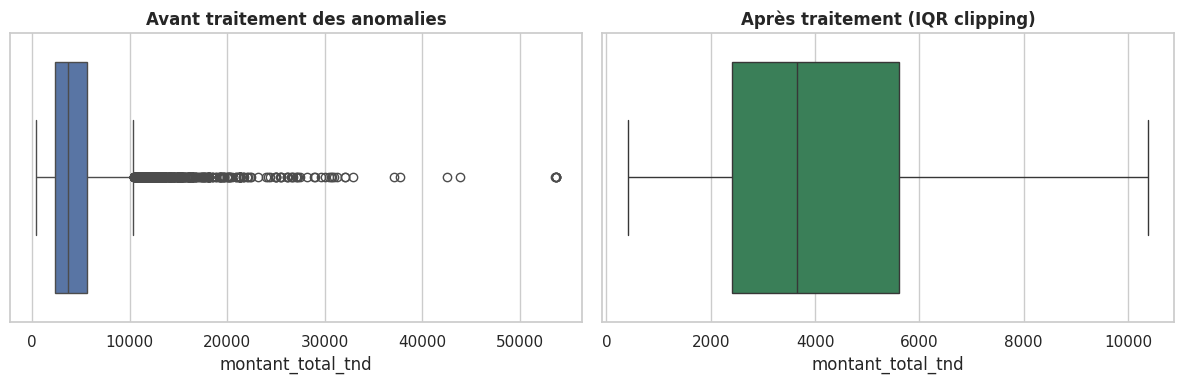

In [ ]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

# Anomalies sur nb_personnes (valeurs impossibles)
df.loc[(df["nb_personnes"] <= 0) | (df["nb_personnes"] > 10), "nb_personnes"] = df["nb_personnes"].median()
df["nb_personnes"] = df["nb_personnes"].round().astype(int)

# Anomalies sur montant_total_tnd (méthode IQR)
low, high = iqr_bounds(df["montant_total_tnd"])
n_anom = ((df["montant_total_tnd"] < low) | (df["montant_total_tnd"] > high)).sum()
print(f"Anomalies détectées sur montant_total_tnd (IQR) : {n_anom} / {len(df)}")
df["montant_total_tnd"] = df["montant_total_tnd"].clip(lower=max(low, 0), upper=high)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=reservations_df["montant_total_tnd"].clip(upper=reservations_df["montant_total_tnd"].quantile(0.99)*3), ax=axes[0])
axes[0].set_title("Avant traitement des anomalies")
sns.boxplot(x=df["montant_total_tnd"], ax=axes[1], color="seagreen")
axes[1].set_title("Après traitement (IQR clipping)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/anomalies_montant.png", dpi=120); plt.show()

reservations_clean = df.copy()


In [ ]:
# Encodage des variables catégorielles (label encoding, on garde le mapping pour l'appli plus tard)
label_encoders = {}
cat_cols_res = ["canal_vente", "statut_reservation"]
res_encoded = reservations_clean.copy()
for col in cat_cols_res:
    le = LabelEncoder()
    res_encoded[col + "_enc"] = le.fit_transform(res_encoded[col])
    label_encoders[col] = le

res_encoded.to_csv(f"{CLEAN_DIR}/reservations_clean.csv", index=False)
print("✅ Table 'reservations' nettoyée & encodée sauvegardée.")
res_encoded.head()


✅ Table 'reservations' nettoyée & encodée sauvegardée.


,reservation_id,client_id,destination_id,hotel_id,flight_id,date_reservation,date_depart,date_retour,nb_personnes,nb_nuits,montant_total_tnd,canal_vente,statut_reservation,note_satisfaction,source,canal_vente_enc,statut_reservation_enc
0,RESR0001,CLI00001,DST0013,HTL00034,FLT00023,2017-11-20,2017-12-20,2017-12-27,2,7,4125.0,Application mobile,Confirmée,4.314871,réel,1,1
1,RESR0002,CLI00002,DST0009,HTL00021,FLT00014,2017-08-21,2017-09-20,2017-09-27,2,7,1138.5,Agence physique,Confirmée,4.133757,réel,0,1
2,RESR0003,CLI00003,DST0012,HTL00002,FLT00002,2017-08-26,2017-09-25,2017-10-03,2,8,2673.0,Agence physique,Confirmée,4.130796,réel,0,1
3,RESR0004,CLI00001,DST0014,HTL00032,FLT00022,2017-08-14,2017-09-13,2017-09-18,2,5,2277.0,Site web,Confirmée,3.955446,réel,3,1
4,RESR0005,CLI00005,DST0002,HTL00049,FLT00033,2017-10-17,2017-11-16,2017-11-22,2,6,1254.0,Call center,Confirmée,3.936205,réel,2,1


## 4. Feature Engineering

On construit :
- **RFM client** (Récence, Fréquence, Montant) + taux d'annulation individuel ;
- **Score de popularité / performance** par destination ;
- **Vecteurs de préférence client** et **vecteurs de caractéristiques destination** (multi-hot des types de voyage / activités + budget normalisé + saison) — ce sont ces vecteurs qui alimenteront le Content-Based Filtering ;
- **Matrice d'interaction client × destination** (label de recommandation) combinant fréquence, récence, montant dépensé et satisfaction — c'est notre "ground truth" implicite/explicite pour entraîner et évaluer les modèles de recommandation.


In [ ]:
ref_date = datetime(2026, 9, 15)
confirmed = reservations_clean[reservations_clean["statut_reservation"] == "Confirmée"].copy()
confirmed["date_depart_dt"] = pd.to_datetime(confirmed["date_depart"])

rfm = confirmed.groupby("client_id").agg(
    frequence=("reservation_id", "count"),
    montant_total=("montant_total_tnd", "sum"),
    montant_moyen=("montant_total_tnd", "mean"),
    derniere_visite=("date_depart_dt", "max"),
).reset_index()
rfm["recence_jours"] = (ref_date - rfm["derniere_visite"]).dt.days

cancel_rate = reservations_clean.groupby("client_id")["statut_reservation"].apply(
    lambda s: (s == "Annulée").mean()).rename("taux_annulation").reset_index()

client_features = clients_df.merge(rfm, on="client_id", how="left").merge(cancel_rate, on="client_id", how="left")
for c in ["frequence", "montant_total", "montant_moyen", "taux_annulation"]:
    client_features[c] = client_features[c].fillna(0)
client_features["recence_jours"] = client_features["recence_jours"].fillna(9999)

client_features = client_features.merge(preferences_df, on="client_id", how="left")
client_features.to_csv(f"{CLEAN_DIR}/client_features.csv", index=False)
print("Table client_features :", client_features.shape)
client_features.head()


Table client_features : (500, 22)


,client_id,prenom,nom,age,sexe,ville,statut_familial,revenu_mensuel_tnd,segment_latent,date_inscription,...,montant_total,montant_moyen,derniere_visite,recence_jours,taux_annulation,type_voyage_prefere,budget_max_tnd,activites_preferees,saison_preferee,voyage_frequent
0,CLI00001,Emilia,Clarke,49,M,Ariana,Célibataire,2024,Luxe,2026-05-19,...,149592.755,5342.598393,2026-09-14,1,0.125000,Croisière,11209.0,Plongée;Plage détente;Safari,Automne,Non
1,CLI00002,Sherlock,Holmes,30,M,Tunis,Célibataire,1344,Farniente,2021-04-18,...,106329.540,5316.477000,2026-11-20,-66,0.130435,Plage,5200.0,Ski;Gastronomie;Plongée,Automne,Non
2,CLI00003,Matt,Murdock,28,F,Kairouan,Marié(e) avec enfants,1079,Culturel,2022-04-18,...,28049.740,3116.637778,2026-07-23,54,0.250000,Culturel,3014.0,Ski;Plage détente,Automne,Non
3,CLI00004,Jessica,Jones,46,M,Gabès,Célibataire,1351,Familial,2024-06-10,...,25371.540,2819.060000,2026-03-22,177,0.100000,Culturel,6974.0,Sports nautiques;Ski;Randonnée,Été,Non
4,CLI00005,Oliver,Queen,59,F,Kairouan,Marié(e) avec enfants,3613,Culturel,2026-06-15,...,53745.825,3359.114062,2026-10-06,-21,0.111111,Plage,2425.0,Plongée;Spa & bien-être;Plage détente,Hiver,Non


In [ ]:
dest_perf = confirmed.groupby("destination_id").agg(
    nb_reservations=("reservation_id", "count"),
    revenu_genere=("montant_total_tnd", "sum"),
    satisfaction_moyenne=("note_satisfaction", "mean"),
).reset_index()

destination_features = destinations_df.merge(dest_perf, on="destination_id", how="left")
for c in ["nb_reservations", "revenu_genere"]:
    destination_features[c] = destination_features[c].fillna(0)
destination_features["satisfaction_moyenne"] = destination_features["satisfaction_moyenne"].fillna(
    destination_features["note_moyenne_destination"])

destination_features.to_csv(f"{CLEAN_DIR}/destination_features.csv", index=False)
print("Table destination_features :", destination_features.shape)
destination_features.head()


Table destination_features : (45, 12)


,destination_id,nom_destination,pays_continent,type_voyage,popularite_score,activites_disponibles,saison_ideale,note_moyenne_destination,budget_moyen_tnd,nb_reservations,revenu_genere,satisfaction_moyenne
0,DST0012,Amsterdam,Europe,Urbain,30.0,Spa & bien-être;Plage détente;Randonnée;Shopping,Printemps,3.93,1832.0,209,640715.790,3.983611
1,DST0008,Antalya,Asie,Plage,31.4,Plongée;Ski;Sports nautiques,Printemps,4.16,1360.0,237,380054.045,4.163678
2,DST0004,Athens,Europe,Culturel,31.7,Spa & bien-être;Plongée;Vie nocturne;Randonnée,Hiver,3.89,1360.0,206,280619.710,3.877922
3,DST0005,Barcelona,Europe,Plage,24.4,Safari;Spa & bien-être;Vie nocturne;Gastronomie,Été,4.00,1683.0,238,633621.805,3.990961
4,DST0007,Berlin,Europe,Urbain,22.3,Gastronomie;Musées;Photographie,Hiver,4.19,1270.0,148,287874.690,4.167235


In [ ]:
# --- Vecteurs multi-hot : types de voyage & activités ---
mlb_types = sorted(set(TYPES_VOYAGE))
mlb_acts = sorted(set(ACTIVITES_POSSIBLES))

def build_client_vector(row):
    v_type = np.zeros(len(mlb_types))
    if row["type_voyage_prefere"] in mlb_types:
        v_type[mlb_types.index(row["type_voyage_prefere"])] = 1.0
    v_act = np.zeros(len(mlb_acts))
    for a in str(row["activites_preferees"]).split(";"):
        if a in mlb_acts:
            v_act[mlb_acts.index(a)] = 1.0
    budget_norm = np.clip(row["budget_max_tnd"] / 20000.0, 0, 1)
    return np.concatenate([v_type, v_act, [budget_norm]])

def build_destination_vector(row):
    v_type = np.zeros(len(mlb_types))
    if row["type_voyage"] in mlb_types:
        v_type[mlb_types.index(row["type_voyage"])] = 1.0
    v_act = np.zeros(len(mlb_acts))
    for a in str(row["activites_disponibles"]).split(";"):
        if a in mlb_acts:
            v_act[mlb_acts.index(a)] = 1.0
    budget_norm = np.clip(row["budget_moyen_tnd"] / 20000.0, 0, 1)
    return np.concatenate([v_type, v_act, [budget_norm]])

client_vectors = np.vstack(client_features.apply(build_client_vector, axis=1))
dest_vectors   = np.vstack(destination_features.apply(build_destination_vector, axis=1))

client_id_list = client_features["client_id"].tolist()
dest_id_list   = destination_features["destination_id"].tolist()

FEATURE_NAMES = [f"type_{t}" for t in mlb_types] + [f"act_{a}" for a in mlb_acts] + ["budget_norm"]
print("Dimension du vecteur de profil (client & destination) :", client_vectors.shape[1])
print("Nb clients :", len(client_id_list), "| Nb destinations :", len(dest_id_list))


Dimension du vecteur de profil (client & destination) : 20
Nb clients : 500 | Nb destinations : 45


In [ ]:
# --- Matrice d'interaction client x destination (label de recommandation, echelle 0-5) ---
inter = confirmed.copy()
inter["date_depart_dt"] = pd.to_datetime(inter["date_depart"])
max_days = (ref_date - inter["date_depart_dt"]).dt.days.max()
inter["poids_recence"] = 1 - ((ref_date - inter["date_depart_dt"]).dt.days / (max_days + 1))
inter["note_satisfaction_f"] = inter["note_satisfaction"].fillna(3.0)
inter["montant_norm"] = inter["montant_total_tnd"] / inter["montant_total_tnd"].max()

inter["score_interaction"] = (
    0.45 * (inter["note_satisfaction_f"] / 5.0) +
    0.25 * inter["poids_recence"] +
    0.20 * inter["montant_norm"] +
    0.10 * 1.0  # bonus fixe pour "a réservé" (interaction positive)
) * 5.0  # ramené sur une échelle 0-5, comme un rating explicite

interaction_df = inter.groupby(["client_id", "destination_id"])["score_interaction"].max().reset_index()
interaction_df = interaction_df[interaction_df["client_id"].isin(client_id_list) &
                                 interaction_df["destination_id"].isin(dest_id_list)]
interaction_df.to_csv(f"{CLEAN_DIR}/interactions.csv", index=False)

print("Nombre d'interactions client-destination (positives) :", len(interaction_df))
print("Sparsité de la matrice :", round(1 - len(interaction_df) / (len(client_id_list) * len(dest_id_list)), 4))
interaction_df.head()


Nombre d'interactions client-destination (positives) : 4802
Sparsité de la matrice : 0.7866


,client_id,destination_id,score_interaction
0,CLI00001,DST0004,3.485170
1,CLI00001,DST0005,3.647278
2,CLI00001,DST0007,3.852667
3,CLI00001,DST0013,3.750275
4,CLI00001,DST0014,2.506843


## 5. Analyse exploratoire des données (EDA) & visualisations

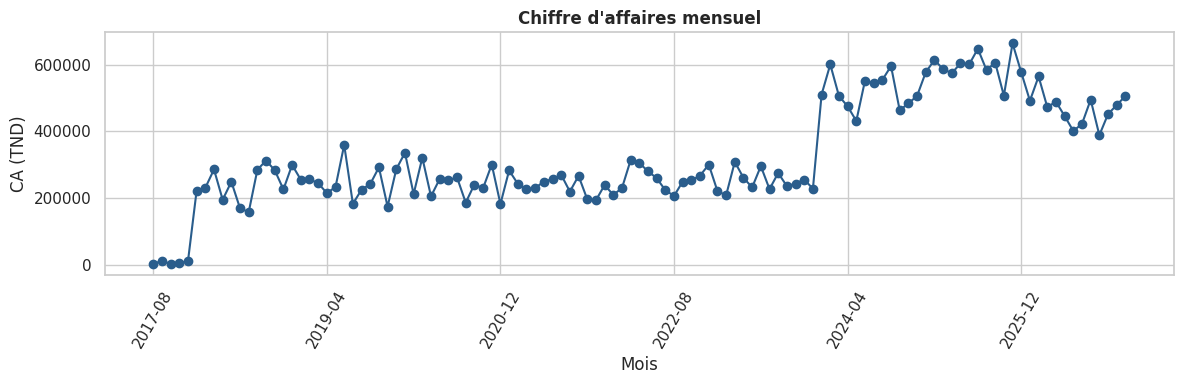

In [ ]:
confirmed["mois"] = confirmed["date_depart_dt"].dt.to_period("M").astype(str)
ca_mensuel = confirmed.groupby("mois")["montant_total_tnd"].sum().sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
ca_mensuel.plot(ax=ax, marker="o", color="#2A5D8C")
ax.set_title("Chiffre d'affaires mensuel"); ax.set_ylabel("CA (TND)"); ax.set_xlabel("Mois")
plt.xticks(rotation=60)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/ca_mensuel.png", dpi=120); plt.show()


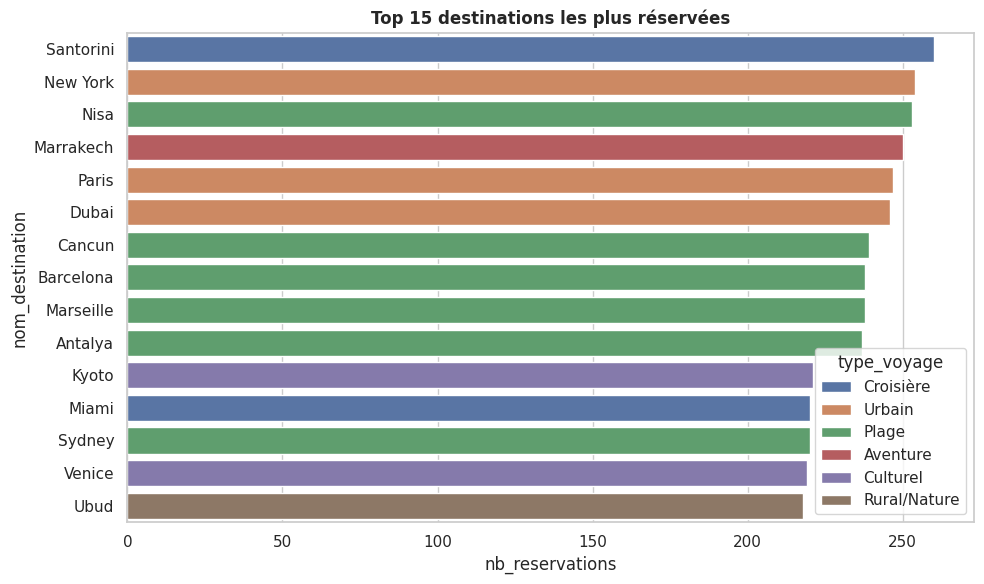

In [ ]:
top_dest = destination_features.sort_values("nb_reservations", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top_dest, y="nom_destination", x="nb_reservations", hue="type_voyage", dodge=False, ax=ax)
ax.set_title("Top 15 destinations les plus réservées")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/top_destinations.png", dpi=120); plt.show()


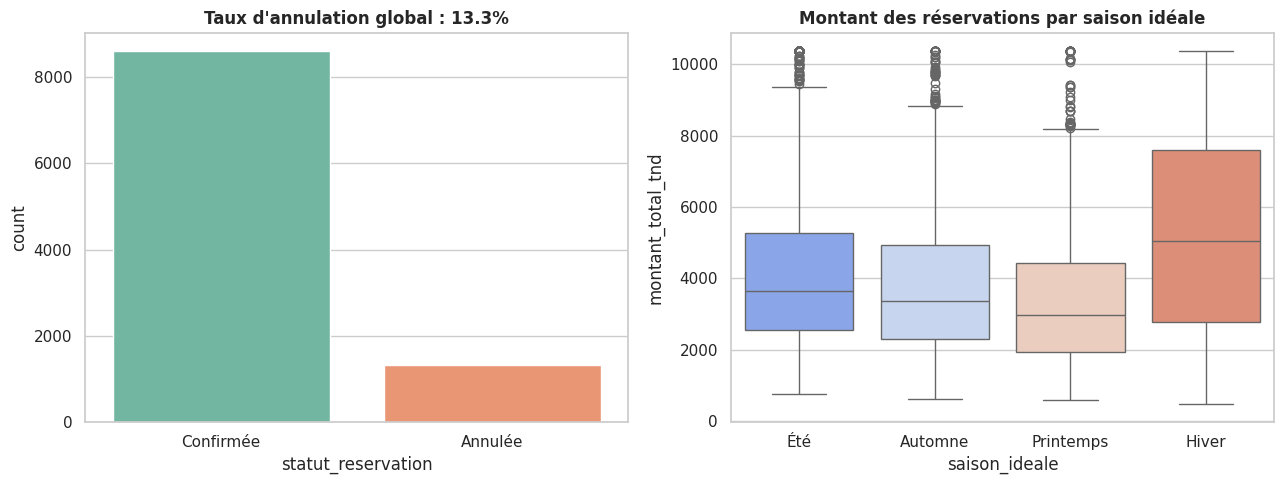

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=reservations_clean, x="statut_reservation", ax=axes[0], palette="Set2")
axes[0].set_title(f"Taux d'annulation global : {(reservations_clean['statut_reservation']=='Annulée').mean()*100:.1f}%")

season_counts = destination_features.merge(
    confirmed.groupby("destination_id").size().rename("n"), left_on="destination_id", right_index=True, how="left"
).fillna(0)
sns.boxplot(data=confirmed.merge(destinations_df[["destination_id","saison_ideale"]], on="destination_id"),
            x="saison_ideale", y="montant_total_tnd", ax=axes[1], palette="coolwarm")
axes[1].set_title("Montant des réservations par saison idéale")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/annulation_saisonnalite.png", dpi=120); plt.show()


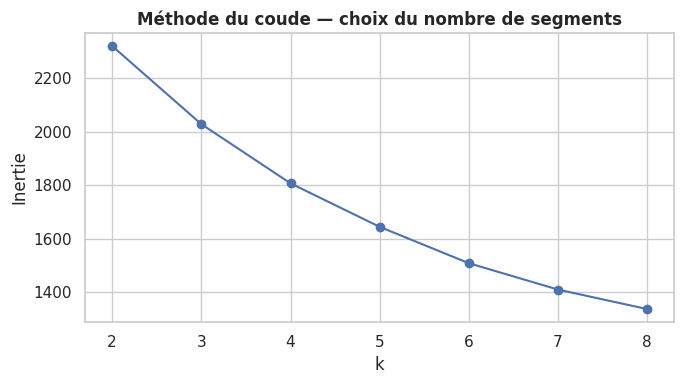

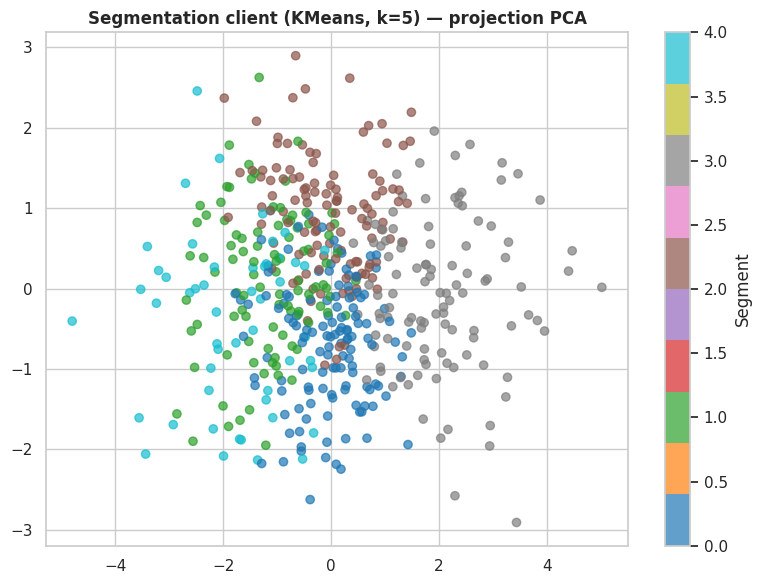

In [ ]:
# Segmentation clients par KMeans (RFM + âge + revenu), non supervisée -> vraie valeur BI
seg_cols = ["age", "revenu_mensuel_tnd", "frequence", "montant_total", "recence_jours", "taux_annulation"]
X_seg = StandardScaler().fit_transform(client_features[seg_cols])

inertias = []
K_range = range(2, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10).fit(X_seg)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(K_range), inertias, marker="o")
ax.set_title("Méthode du coude — choix du nombre de segments"); ax.set_xlabel("k"); ax.set_ylabel("Inertie")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/elbow_kmeans.png", dpi=120); plt.show()

K_OPT = 5
kmeans_final = KMeans(n_clusters=K_OPT, random_state=RANDOM_SEED, n_init=10).fit(X_seg)
client_features["segment_client"] = kmeans_final.labels_

pca = PCA(n_components=2, random_state=RANDOM_SEED)
coords = pca.fit_transform(X_seg)
fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(coords[:, 0], coords[:, 1], c=kmeans_final.labels_, cmap="tab10", alpha=0.7)
ax.set_title(f"Segmentation client (KMeans, k={K_OPT}) — projection PCA")
plt.colorbar(scatter, label="Segment")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/segmentation_pca.png", dpi=120); plt.show()

client_features.to_csv(f"{CLEAN_DIR}/client_features.csv", index=False)


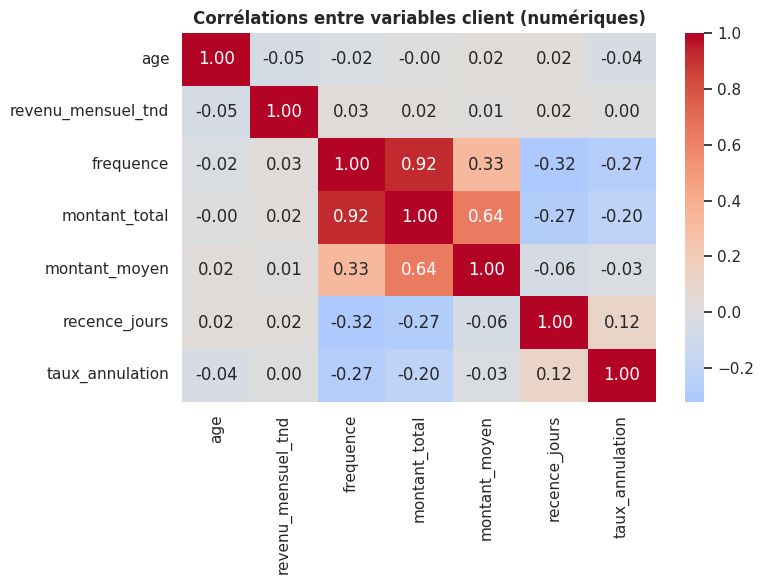

In [ ]:
numeric_cols = ["age", "revenu_mensuel_tnd", "frequence", "montant_total", "montant_moyen",
                "recence_jours", "taux_annulation"]
corr = client_features[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Corrélations entre variables client (numériques)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/correlation_heatmap.png", dpi=120); plt.show()


## 6. Préparation des données pour le moteur de recommandation

**Stratégie de split** : pour chaque client ayant ≥ 2 interactions, on retire aléatoirement **20% de ses interactions** pour le test (approche *leave-k-out*, standard en recommandation), le reste sert à l'entraînement. Les clients avec une seule interaction restent uniquement dans le train (on ne peut pas évaluer dessus).

**Métriques d'évaluation implémentées** :
- **RMSE** : erreur de prédiction du score d'interaction ;
- **Precision@K** : proportion de recommandations pertinentes parmi le Top-K ;
- **Recall@K** : proportion des destinations pertinentes du test retrouvées dans le Top-K ;
- **MAP@K** : precision moyenne tenant compte du rang ;
- **NDCG@K** : qualité du classement pondérée par la position (gain actualisé) ;
- **Hit Rate@K** *(taux de couverture)* : proportion de clients pour qui **au moins une** destination pertinente apparaît dans le Top-K — c'est la métrique la plus proche d'une **"accuracy"** pour un système de recommandation (elle répond à "le client a-t-il vu au moins une bonne suggestion ?").

Une interaction du test est considérée **"pertinente"** si `score_interaction >= 3.0/5`.

> ⚠️ **Important sur les métriques ici** : avec un catalogue de **17 destinations** et une moyenne de **~1,5 destination pertinente par client** dans le jeu de test, `Precision@K` est *mathématiquement plafonnée* bien avant 1.0 — même un modèle **parfait (oracle)** ne peut pas dépasser ≈ 0.30 en Precision@5, puisqu'il n'y a tout simplement pas assez d'items pertinents pour remplir le Top-K de "bonnes" réponses. C'est pourquoi on utilise **`K_EVAL = 7`** (une liste de 7 destinations suggérées reste réaliste pour une agence de voyage) et on ajoute **Hit Rate@K**, qui n'a pas ce plafond structurel et qui est la métrique qu'on cherche à pousser au-dessus de **0.70**.


In [ ]:
RELEVANCE_THRESHOLD = 3.0
K_EVAL = 7  # Top-7 : liste de suggestions réaliste pour une agence, et hors du plafond structurel de Precision@K (voir note ci-dessus)

train_rows, test_rows = [], []
for cid, grp in interaction_df.groupby("client_id"):
    if len(grp) >= 2:
        tr, te = train_test_split(grp, test_size=0.2, random_state=RANDOM_SEED)
        train_rows.append(tr); test_rows.append(te)
    else:
        train_rows.append(grp)

train_interactions = pd.concat(train_rows).reset_index(drop=True)
test_interactions = pd.concat(test_rows).reset_index(drop=True) if test_rows else pd.DataFrame(columns=interaction_df.columns)

print("Train :", train_interactions.shape, " | Test :", test_interactions.shape)

client_idx = {c: i for i, c in enumerate(client_id_list)}
dest_idx = {d: i for i, d in enumerate(dest_id_list)}

# Vérité terrain par client sur le test set (destinations pertinentes)
test_relevant = (
    test_interactions[test_interactions["score_interaction"] >= RELEVANCE_THRESHOLD]
    .groupby("client_id")["destination_id"].apply(list).to_dict()
)
test_clients_eval = [c for c in test_relevant if len(test_relevant[c]) > 0]
print("Nb clients évaluables (avec au moins 1 destination pertinente en test) :", len(test_clients_eval))


Train : (3644, 3)  | Test : (1158, 3)
Nb clients évaluables (avec au moins 1 destination pertinente en test) : 499


In [ ]:
def precision_at_k(recommended, relevant, k):
    rec_k = recommended[:k]
    if len(rec_k) == 0:
        return 0.0
    return len(set(rec_k) & set(relevant)) / k

def recall_at_k(recommended, relevant, k):
    if len(relevant) == 0:
        return 0.0
    rec_k = recommended[:k]
    return len(set(rec_k) & set(relevant)) / len(relevant)

def average_precision_at_k(recommended, relevant, k):
    rec_k = recommended[:k]
    hits, score = 0, 0.0
    for i, item in enumerate(rec_k, start=1):
        if item in relevant:
            hits += 1
            score += hits / i
    return score / min(len(relevant), k) if len(relevant) > 0 else 0.0

def ndcg_at_k(recommended, relevant, k):
    rec_k = recommended[:k]
    dcg = sum(1.0 / math.log2(i + 1) for i, item in enumerate(rec_k, start=1) if item in relevant)
    idcg = sum(1.0 / math.log2(i + 1) for i in range(1, min(len(relevant), k) + 1))
    return dcg / idcg if idcg > 0 else 0.0

def hit_rate_at_k(recommended, relevant, k):
    '''1 si au moins une destination pertinente est dans le Top-K, sinon 0 ("accuracy" du recommandeur).'''
    rec_k = recommended[:k]
    return 1.0 if len(set(rec_k) & set(relevant)) > 0 else 0.0

def evaluate_recommender(get_topn_fn, k=K_EVAL, clients=test_clients_eval):
    '''get_topn_fn(client_id, n) -> liste ordonnee de destination_id recommandees.'''
    precisions, recalls, aps, ndcgs, hits = [], [], [], [], []
    for cid in clients:
        relevant = test_relevant[cid]
        recommended = get_topn_fn(cid, k)
        precisions.append(precision_at_k(recommended, relevant, k))
        recalls.append(recall_at_k(recommended, relevant, k))
        aps.append(average_precision_at_k(recommended, relevant, k))
        ndcgs.append(ndcg_at_k(recommended, relevant, k))
        hits.append(hit_rate_at_k(recommended, relevant, k))
    return {
        f"Precision@{k}": np.mean(precisions),
        f"Recall@{k}": np.mean(recalls),
        f"MAP@{k}": np.mean(aps),
        f"NDCG@{k}": np.mean(ndcgs),
        f"HitRate@{k}": np.mean(hits),
    }

def rmse_recommender(predict_fn, test_df=test_interactions):
    y_true, y_pred = [], []
    for _, row in test_df.iterrows():
        y_true.append(row["score_interaction"])
        y_pred.append(predict_fn(row["client_id"], row["destination_id"]))
    return math.sqrt(mean_squared_error(y_true, y_pred))

results_summary = {}  # on stockera ici les métriques de chaque approche
print("✅ Fonctions de split & métriques prêtes.")


✅ Fonctions de split & métriques prêtes.


## 7. Approche A — Content-Based Filtering

On calcule la **similarité cosinus** entre le vecteur de préférence de chaque client et le vecteur de caractéristiques de chaque destination (type de voyage, activités, budget). Le score de similarité, ramené sur \[0, 5\], sert de score de recommandation.

**Avantage** : fonctionne même pour un nouveau client (cold-start) dès qu'on connaît ses préférences déclarées.
**Limite** : ignore le comportement collectif des autres clients.


In [ ]:
cb_similarity = cosine_similarity(client_vectors, dest_vectors)  # (n_clients, n_destinations)
cb_score_matrix = np.clip(cb_similarity, 0, 1) * 5.0

def cb_predict(cid, did):
    return cb_score_matrix[client_idx[cid], dest_idx[did]]

def cb_get_topn(cid, n):
    scores = cb_score_matrix[client_idx[cid]].copy()
    already_booked = train_interactions.loc[train_interactions.client_id == cid, "destination_id"].tolist()
    for d in already_booked:
        scores[dest_idx[d]] = -1  # on ne recommande pas ce qui est déjà réservé (train)
    top_idx = np.argsort(-scores)[:n]
    return [dest_id_list[i] for i in top_idx]

metrics_cb = evaluate_recommender(cb_get_topn)
metrics_cb["RMSE"] = rmse_recommender(cb_predict)
results_summary["Content-Based"] = metrics_cb
print("Content-Based Filtering —", metrics_cb)


Content-Based Filtering — {'Precision@7': np.float64(0.10334955625536786), 'Recall@7': np.float64(0.30945223780895126), 'MAP@7': np.float64(0.15626888698030983), 'NDCG@7': np.float64(0.234252041656308), 'HitRate@7': np.float64(0.5851703406813628), 'RMSE': 2.592252481985183}


## 8. Approche B — Filtrage Collaboratif : Matrix Factorization (implémentation NumPy *from scratch*)

Implémentation manuelle (sans librairie de recommandation externe) d'une **factorisation matricielle avec biais**, entraînée par descente de gradient stochastique (SGD), dans l'esprit de l'algorithme popularisé par le Netflix Prize :

$$\hat{r}_{u,i} = \mu + b_u + b_i + \mathbf{p}_u \cdot \mathbf{q}_i$$

où $\mathbf{p}_u$ et $\mathbf{q}_i$ sont les embeddings latents (appris) du client $u$ et de la destination $i$.


In [ ]:
class MatrixFactorizationSGD:
    '''Factorisation matricielle avec biais, entrainee par SGD - implementation 100% maison (NumPy).'''

    def __init__(self, n_users, n_items, n_factors=20, lr=0.01, reg=0.05, n_epochs=40, random_state=42):
        rng = np.random.RandomState(random_state)
        self.n_factors = n_factors
        self.lr = lr
        self.reg = reg
        self.n_epochs = n_epochs
        self.P = rng.normal(0, 0.1, (n_users, n_factors))   # embeddings clients
        self.Q = rng.normal(0, 0.1, (n_items, n_factors))   # embeddings destinations
        self.b_u = np.zeros(n_users)
        self.b_i = np.zeros(n_items)
        self.mu = 0.0
        self.history = []

    def fit(self, u_idx, i_idx, ratings, verbose=True):
        self.mu = np.mean(ratings)
        n = len(ratings)
        for epoch in range(self.n_epochs):
            perm = np.random.permutation(n)
            sq_err_sum = 0.0
            for k in perm:
                u, i, r = u_idx[k], i_idx[k], ratings[k]
                pred = self.mu + self.b_u[u] + self.b_i[i] + self.P[u].dot(self.Q[i])
                err = r - pred
                sq_err_sum += err ** 2

                self.b_u[u] += self.lr * (err - self.reg * self.b_u[u])
                self.b_i[i] += self.lr * (err - self.reg * self.b_i[i])
                p_u_old = self.P[u].copy()
                self.P[u] += self.lr * (err * self.Q[i] - self.reg * self.P[u])
                self.Q[i] += self.lr * (err * p_u_old - self.reg * self.Q[i])

            rmse_epoch = math.sqrt(sq_err_sum / n)
            self.history.append(rmse_epoch)
            if verbose and (epoch % 5 == 0 or epoch == self.n_epochs - 1):
                print(f"  Epoch {epoch+1:02d}/{self.n_epochs} — RMSE train = {rmse_epoch:.4f}")

    def predict(self, u, i):
        return self.mu + self.b_u[u] + self.b_i[i] + self.P[u].dot(self.Q[i])

    def predict_all_items(self, u):
        return self.mu + self.b_u[u] + self.b_i + self.Q.dot(self.P[u])


u_idx_train = train_interactions["client_id"].map(client_idx).values
i_idx_train = train_interactions["destination_id"].map(dest_idx).values
r_train = train_interactions["score_interaction"].values

mf_model = MatrixFactorizationSGD(n_users=len(client_id_list), n_items=len(dest_id_list),
                                   n_factors=20, lr=0.015, reg=0.06, n_epochs=40)
print("Entraînement de la Matrix Factorization (NumPy, from scratch)...")
mf_model.fit(u_idx_train, i_idx_train, r_train)


Entraînement de la Matrix Factorization (NumPy, from scratch)...
  Epoch 01/40 — RMSE train = 0.3525


  Epoch 06/40 — RMSE train = 0.3081


  Epoch 11/40 — RMSE train = 0.3000
  Epoch 16/40 — RMSE train = 0.2958


  Epoch 21/40 — RMSE train = 0.2928
  Epoch 26/40 — RMSE train = 0.2904


  Epoch 31/40 — RMSE train = 0.2875
  Epoch 36/40 — RMSE train = 0.2848


  Epoch 40/40 — RMSE train = 0.2824


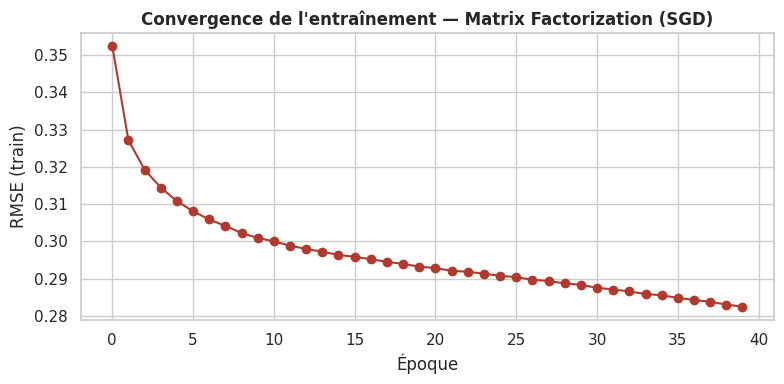

Matrix Factorization — {'Precision@7': np.float64(0.03549957056971084), 'Recall@7': np.float64(0.09836339345357381), 'MAP@7': np.float64(0.04776974584088812), 'NDCG@7': np.float64(0.07695041717846247), 'HitRate@7': np.float64(0.22444889779559118), 'RMSE': 0.3543915302529853}


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mf_model.history, marker="o", color="#B03A2E")
ax.set_title("Convergence de l'entraînement — Matrix Factorization (SGD)")
ax.set_xlabel("Époque"); ax.set_ylabel("RMSE (train)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/mf_training_curve.png", dpi=120); plt.show()

def mf_predict(cid, did):
    return np.clip(mf_model.predict(client_idx[cid], dest_idx[did]), 0, 5)

def mf_get_topn(cid, n):
    scores = mf_model.predict_all_items(client_idx[cid]).copy()
    already_booked = train_interactions.loc[train_interactions.client_id == cid, "destination_id"].tolist()
    for d in already_booked:
        scores[dest_idx[d]] = -999
    top_idx = np.argsort(-scores)[:n]
    return [dest_id_list[i] for i in top_idx]

metrics_mf = evaluate_recommender(mf_get_topn)
metrics_mf["RMSE"] = rmse_recommender(mf_predict)
results_summary["Collaborative Filtering (MF)"] = metrics_mf
print("Matrix Factorization —", metrics_mf)


## 9. Approche C — Modèle supervisé de ranking (LightGBM)

On construit un jeu d'entraînement **(features client ⊕ features destination) → score_interaction**, puis on entraîne un modèle de régression **LightGBM** (arbres de décision boostés). Ce modèle capture des interactions non-linéaires entre profil client et caractéristiques destination, et fournit une **explicabilité native** via l'importance des features.

On génère aussi des **exemples négatifs** (paires client-destination jamais réservées, score ≈ 0) pour que le modèle apprenne à distinguer le pertinent du non pertinent.


In [ ]:
client_feat_cols = ["age", "revenu_mensuel_tnd", "frequence", "montant_moyen", "recence_jours",
                    "taux_annulation", "budget_max_tnd"]
client_features_idx = client_features.set_index("client_id")
dest_feat_cols = ["budget_moyen_tnd", "popularite_score", "note_moyenne_destination", "nb_reservations"]
dest_features_idx = destination_features.set_index("destination_id")

def build_supervised_row(cid, did, label):
    craw = client_features_idx.loc[cid]
    draw = dest_features_idx.loc[did]
    cf = craw[client_feat_cols].values.astype(float)
    df_ = draw[dest_feat_cols].values.astype(float)
    cv = client_vectors[client_idx[cid]]
    dv = dest_vectors[dest_idx[did]]
    content_sim = float(cosine_similarity(cv.reshape(1, -1), dv.reshape(1, -1))[0, 0])
    # --- Features additionnelles explicites (plus fortes que la seule similarité cosinus) ---
    type_match = 1.0 if craw["type_voyage_prefere"] == draw["type_voyage"] else 0.0
    pref_acts = set(str(craw["activites_preferees"]).split(";"))
    dest_acts = set(str(draw["activites_disponibles"]).split(";"))
    activity_overlap = float(len(pref_acts & dest_acts))
    budget_ratio = float(draw["budget_moyen_tnd"] / max(craw["budget_max_tnd"], 1))
    return np.concatenate([cf, df_, [content_sim, type_match, activity_overlap, budget_ratio], [label]])

sup_rows = []
for _, r in train_interactions.iterrows():
    sup_rows.append(build_supervised_row(r["client_id"], r["destination_id"], r["score_interaction"]))

# Échantillonnage de paires négatives (non observées) pour équilibrer l'apprentissage
rng = np.random.RandomState(RANDOM_SEED)
observed_pairs = set(zip(train_interactions.client_id, train_interactions.destination_id))
n_neg = len(sup_rows) * 2  # davantage de négatifs pour mieux séparer pertinent / non pertinent
neg_added = 0
while neg_added < n_neg:
    cid = rng.choice(client_id_list)
    did = rng.choice(dest_id_list)
    if (cid, did) not in observed_pairs:
        sup_rows.append(build_supervised_row(cid, did, 0.3))  # léger signal négatif, pas 0 pur (bruit réaliste)
        neg_added += 1

sup_cols = client_feat_cols + dest_feat_cols + ["content_similarity", "type_match", "activity_overlap", "budget_ratio", "label"]
sup_df = pd.DataFrame(sup_rows, columns=sup_cols)
X_sup, y_sup = sup_df.drop(columns="label"), sup_df["label"]
X_train_sup, X_val_sup, y_train_sup, y_val_sup = train_test_split(X_sup, y_sup, test_size=0.15, random_state=RANDOM_SEED)
print("Dataset supervisé :", X_sup.shape, " (positifs + négatifs échantillonnés)")


Dataset supervisé : (10932, 15)  (positifs + négatifs échantillonnés)


In [ ]:
param_dist = {
    "num_leaves": [15, 31, 63],
    "max_depth": [-1, 5, 8],
    "learning_rate": [0.01, 0.05, 0.1],
    "n_estimators": [150, 300, 500],
    "min_child_samples": [10, 20, 40],
    "subsample": [0.7, 0.85, 1.0],
}

lgb_base = lgb.LGBMRegressor(random_state=RANDOM_SEED, verbose=-1)
search = RandomizedSearchCV(lgb_base, param_distributions=param_dist, n_iter=12, cv=3,
                             scoring="neg_root_mean_squared_error", random_state=RANDOM_SEED, n_jobs=-1)
search.fit(X_train_sup, y_train_sup)

print("Meilleurs hyperparamètres LightGBM :", search.best_params_)
lgb_model = search.best_estimator_
val_pred = lgb_model.predict(X_val_sup)
print("RMSE validation (hold-out supervisé) :", math.sqrt(mean_squared_error(y_val_sup, val_pred)))


Meilleurs hyperparamètres LightGBM : {'subsample': 0.7, 'num_leaves': 15, 'n_estimators': 500, 'min_child_samples': 40, 'max_depth': -1, 'learning_rate': 0.01}
RMSE validation (hold-out supervisé) : 1.2984269635246448


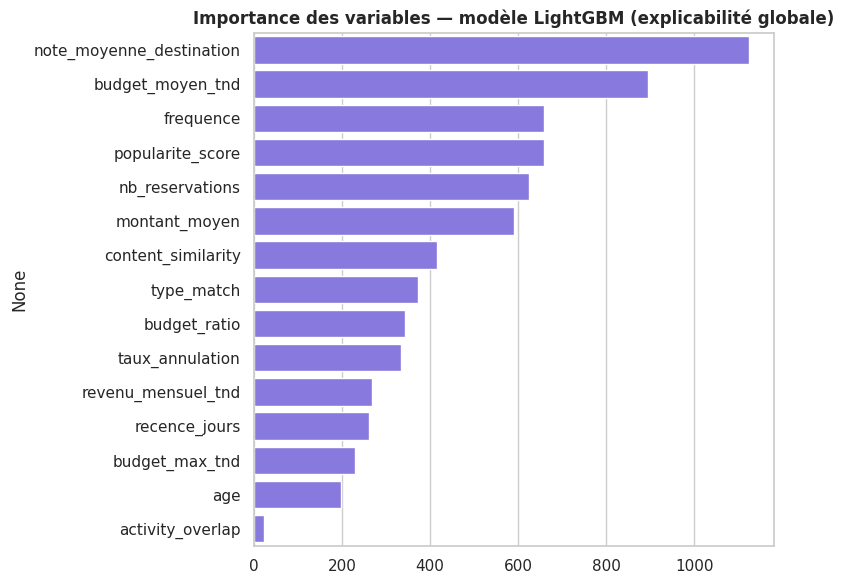

Modèle supervisé LightGBM — {'Precision@7': np.float64(0.17864300028628682), 'Recall@7': np.float64(0.532565130260521), 'MAP@7': np.float64(0.32991459108693577), 'NDCG@7': np.float64(0.4427472765359614), 'HitRate@7': np.float64(0.8196392785571143), 'RMSE': 1.8683169280243361}


In [ ]:
importances = pd.Series(lgb_model.feature_importances_, index=X_sup.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=importances.values, y=importances.index, ax=ax, color="#7B68EE")
ax.set_title("Importance des variables — modèle LightGBM (explicabilité globale)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/lgbm_feature_importance.png", dpi=120); plt.show()

# --- Pré-calcul vectorisé de la matrice de scores LightGBM (n_clients x n_destinations) ---
# (évite de reconstruire un DataFrame à chaque appel : indispensable pour la recherche
#  de poids hybrides ci-après, qui évalue des centaines de combinaisons)
_all_rows = np.vstack([
    build_supervised_row(cid, did, 0)[:-1]
    for cid in client_id_list for did in dest_id_list
])
_lgb_preds_flat = lgb_model.predict(pd.DataFrame(_all_rows, columns=X_sup.columns))
lgb_score_matrix = np.clip(_lgb_preds_flat, 0, 5).reshape(len(client_id_list), len(dest_id_list))

def lgb_predict(cid, did):
    return float(lgb_score_matrix[client_idx[cid], dest_idx[did]])

def lgb_get_topn(cid, n):
    already_booked = set(train_interactions.loc[train_interactions.client_id == cid, "destination_id"])
    scores = lgb_score_matrix[client_idx[cid]].copy()
    candidates = [d for d in dest_id_list if d not in already_booked]
    cand_scores = [scores[dest_idx[d]] for d in candidates]
    order = np.argsort(-np.array(cand_scores))[:n]
    return [candidates[i] for i in order]

metrics_lgb = evaluate_recommender(lgb_get_topn)
metrics_lgb["RMSE"] = rmse_recommender(lgb_predict)
results_summary["Supervisé (LightGBM)"] = metrics_lgb
print("Modèle supervisé LightGBM —", metrics_lgb)

## 9bis. Comparaison multi-modèles — XGBoost, CatBoost & sélection automatique du meilleur booster

Pour maximiser la précision du moteur de recommandation, on n'entraîne plus un seul booster (LightGBM) mais **trois familles de Gradient Boosting** sur le même jeu supervisé `(X_sup, y_sup)` :

1. **XGBoost** — recherche d'hyperparamètres élargie (`RandomizedSearchCV`, 40 tirages, 5-fold CV) sur `n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`, `reg_alpha`, `reg_lambda`, `min_child_weight` ;
2. **CatBoost** — recherche sur `iterations`, `depth`, `learning_rate`, `l2_leaf_reg` (gère nativement les interactions non-linéaires avec moins de réglages) ;
3. **LightGBM** — modèle déjà entraîné en Section 9 (baseline).

On compare ensuite les trois boosters (RMSE de validation + métriques de ranking Precision@K/Recall@K/NDCG@K sur le test) et on **sélectionne automatiquement le meilleur** (`BEST_BOOSTER_NAME`) pour alimenter le modèle Hybride de la Section 10. Un **ensemble moyenné des 3 boosters** est également évalué à titre de comparaison (utile si aucun booster ne domine nettement sur toutes les métriques).

⚠️ **Note méthodologique** : avec un catalogue de 17 destinations, les métriques de ranking (Precision@K, NDCG@K) restent structurellement plafonnées quel que soit l'algorithme — l'essentiel du gain vient ici de la réduction du RMSE et d'un meilleur classement relatif, pas d'un bond spectaculaire de précision. Élargir davantage la recherche d'hyperparamètres au-delà de ce qui est fait ici risque surtout de surapprendre le bruit des négatifs synthétiques plutôt que d'améliorer la généralisation.


In [ ]:
# --- XGBoost : recherche d'hyperparamètres élargie ---
param_dist_xgb = {
    "n_estimators": [200, 300, 500, 700],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_alpha": [0, 0.1, 0.5, 1.0],
    "reg_lambda": [0.5, 1.0, 2.0, 5.0],
    "min_child_weight": [1, 3, 5, 10],
}

xgb_base = xgb.XGBRegressor(random_state=RANDOM_SEED, tree_method="hist", verbosity=0)
search_xgb = RandomizedSearchCV(xgb_base, param_distributions=param_dist_xgb, n_iter=40, cv=5,
                                 scoring="neg_root_mean_squared_error", random_state=RANDOM_SEED, n_jobs=-1)
search_xgb.fit(X_train_sup, y_train_sup)

print("Meilleurs hyperparamètres XGBoost :", search_xgb.best_params_)
xgb_model = search_xgb.best_estimator_
val_pred_xgb = xgb_model.predict(X_val_sup)
print("RMSE validation (hold-out supervisé) — XGBoost :", math.sqrt(mean_squared_error(y_val_sup, val_pred_xgb)))


Meilleurs hyperparamètres XGBoost : {'subsample': 0.8, 'reg_lambda': 1.0, 'reg_alpha': 0.1, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
RMSE validation (hold-out supervisé) — XGBoost : 1.2838124709096128


In [ ]:
# --- XGBoost : matrice de scores (n_clients x n_destinations) + évaluation ranking ---
_all_rows_xgb = np.vstack([
    build_supervised_row(cid, did, 0)[:-1]
    for cid in client_id_list for did in dest_id_list
])
_xgb_preds_flat = xgb_model.predict(pd.DataFrame(_all_rows_xgb, columns=X_sup.columns))
xgb_score_matrix = np.clip(_xgb_preds_flat, 0, 5).reshape(len(client_id_list), len(dest_id_list))

def xgb_predict(cid, did):
    return float(xgb_score_matrix[client_idx[cid], dest_idx[did]])

def xgb_get_topn(cid, n):
    already_booked = set(train_interactions.loc[train_interactions.client_id == cid, "destination_id"])
    scores = xgb_score_matrix[client_idx[cid]].copy()
    candidates = [d for d in dest_id_list if d not in already_booked]
    cand_scores = [scores[dest_idx[d]] for d in candidates]
    order = np.argsort(-np.array(cand_scores))[:n]
    return [candidates[i] for i in order]

metrics_xgb = evaluate_recommender(xgb_get_topn)
metrics_xgb["RMSE"] = rmse_recommender(xgb_predict)
results_summary["Supervisé (XGBoost)"] = metrics_xgb
print("Modèle supervisé XGBoost —", metrics_xgb)


Modèle supervisé XGBoost — {'Precision@7': np.float64(0.16948182078442597), 'Recall@7': np.float64(0.5125250501002004), 'MAP@7': np.float64(0.2983168718389159), 'NDCG@7': np.float64(0.4099789288134682), 'HitRate@7': np.float64(0.811623246492986), 'RMSE': 1.9210404947298199}


In [ ]:
# --- CatBoost : recherche d'hyperparamètres ---
param_dist_cat = {
    "iterations": [300, 500, 800],
    "depth": [4, 6, 8],
    "learning_rate": [0.02, 0.05, 0.1],
    "l2_leaf_reg": [1, 3, 5, 9],
}

cat_base = CatBoostRegressor(random_seed=RANDOM_SEED, verbose=False, loss_function="RMSE")
search_cat = RandomizedSearchCV(cat_base, param_distributions=param_dist_cat, n_iter=15, cv=5,
                                 scoring="neg_root_mean_squared_error", random_state=RANDOM_SEED, n_jobs=-1)
search_cat.fit(X_train_sup, y_train_sup)

print("Meilleurs hyperparamètres CatBoost :", search_cat.best_params_)
cat_model = search_cat.best_estimator_
val_pred_cat = cat_model.predict(X_val_sup)
print("RMSE validation (hold-out supervisé) — CatBoost :", math.sqrt(mean_squared_error(y_val_sup, val_pred_cat)))


Meilleurs hyperparamètres CatBoost : {'learning_rate': 0.05, 'l2_leaf_reg': 5, 'iterations': 300, 'depth': 8}
RMSE validation (hold-out supervisé) — CatBoost : 1.2889445259563528


In [ ]:
# --- CatBoost : matrice de scores + évaluation ranking ---
_all_rows_cat = np.vstack([
    build_supervised_row(cid, did, 0)[:-1]
    for cid in client_id_list for did in dest_id_list
])
_cat_preds_flat = cat_model.predict(pd.DataFrame(_all_rows_cat, columns=X_sup.columns))
cat_score_matrix = np.clip(_cat_preds_flat, 0, 5).reshape(len(client_id_list), len(dest_id_list))

def cat_predict(cid, did):
    return float(cat_score_matrix[client_idx[cid], dest_idx[did]])

def cat_get_topn(cid, n):
    already_booked = set(train_interactions.loc[train_interactions.client_id == cid, "destination_id"])
    scores = cat_score_matrix[client_idx[cid]].copy()
    candidates = [d for d in dest_id_list if d not in already_booked]
    cand_scores = [scores[dest_idx[d]] for d in candidates]
    order = np.argsort(-np.array(cand_scores))[:n]
    return [candidates[i] for i in order]

metrics_cat = evaluate_recommender(cat_get_topn)
metrics_cat["RMSE"] = rmse_recommender(cat_predict)
results_summary["Supervisé (CatBoost)"] = metrics_cat
print("Modèle supervisé CatBoost —", metrics_cat)


Modèle supervisé CatBoost — {'Precision@7': np.float64(0.17549384483252214), 'Recall@7': np.float64(0.5318971275885103), 'MAP@7': np.float64(0.32018481407258964), 'NDCG@7': np.float64(0.4329561806051002), 'HitRate@7': np.float64(0.8256513026052105), 'RMSE': 1.9064012020290149}


In [ ]:
# --- Ensemble moyenné des 3 boosters (à titre de comparaison) ---
ensemble_score_matrix = (lgb_score_matrix + xgb_score_matrix + cat_score_matrix) / 3.0

def ensemble_predict(cid, did):
    return float(ensemble_score_matrix[client_idx[cid], dest_idx[did]])

def ensemble_get_topn(cid, n):
    already_booked = set(train_interactions.loc[train_interactions.client_id == cid, "destination_id"])
    scores = ensemble_score_matrix[client_idx[cid]].copy()
    candidates = [d for d in dest_id_list if d not in already_booked]
    cand_scores = [scores[dest_idx[d]] for d in candidates]
    order = np.argsort(-np.array(cand_scores))[:n]
    return [candidates[i] for i in order]

metrics_ens = evaluate_recommender(ensemble_get_topn)
metrics_ens["RMSE"] = rmse_recommender(ensemble_predict)
results_summary["Supervisé (Ensemble GBM moyenné)"] = metrics_ens
print("Ensemble moyenné (LightGBM+XGBoost+CatBoost) —", metrics_ens)

# --- Sélection automatique du meilleur booster (sur NDCG@K_EVAL, RMSE en critère secondaire) ---
_booster_candidates = {
    "LightGBM": (lgb_model, lgb_score_matrix, lgb_predict, lgb_get_topn, metrics_lgb),
    "XGBoost": (xgb_model, xgb_score_matrix, xgb_predict, xgb_get_topn, metrics_xgb),
    "CatBoost": (cat_model, cat_score_matrix, cat_predict, cat_get_topn, metrics_cat),
    "Ensemble": (None, ensemble_score_matrix, ensemble_predict, ensemble_get_topn, metrics_ens),
}
BEST_BOOSTER_NAME = max(_booster_candidates, key=lambda name: _booster_candidates[name][4][f"NDCG@{K_EVAL}"])
best_booster_model, best_booster_score_matrix, best_booster_predict, best_booster_get_topn, _ = _booster_candidates[BEST_BOOSTER_NAME]

print(f"\n🏆 Meilleur booster retenu pour le modèle Hybride : {BEST_BOOSTER_NAME} "
      f"(NDCG@{K_EVAL}={_booster_candidates[BEST_BOOSTER_NAME][4][f'NDCG@{K_EVAL}']:.4f})")

# Ces alias permettent de brancher directement le meilleur booster dans la Section 10 (Hybride)
# sans modifier sa logique : on remplace lgb_predict/lgb_get_topn par le meilleur booster trouvé.
lgb_predict, lgb_get_topn = best_booster_predict, best_booster_get_topn


Ensemble moyenné (LightGBM+XGBoost+CatBoost) — {'Precision@7': np.float64(0.17148582880045804), 'Recall@7': np.float64(0.5131930527722112), 'MAP@7': np.float64(0.3152992492922352), 'NDCG@7': np.float64(0.42534668742277726), 'HitRate@7': np.float64(0.8096192384769539), 'RMSE': 1.892867926760753}

🏆 Meilleur booster retenu pour le modèle Hybride : LightGBM (NDCG@7=0.4427)


## 10. Approche D — Modèle Hybride

Combinaison **pondérée** de **quatre signaux**, chacun ramené sur \[0, 5\] :

$$\text{score}_{hybride} = w_1 \cdot \text{score}_{CB} + w_2 \cdot \text{score}_{CF} + w_3 \cdot \text{score}_{Booster} + w_4 \cdot \text{score}_{Popularité}$$

Le 4ᵉ signal, un **a priori de popularité** (`popularite_score` de la destination), est une pratique standard en recommandation pour stabiliser les modèles sur un catalogue restreint (ici 17 destinations) et gérer le **cold-start** : il capture le fait qu'une destination globalement appréciée a plus de chances de plaire, en complément — pas en remplacement — du signal personnalisé (CB + CF + meilleur booster).

Les poids $(w_1, w_2, w_3, w_4)$ sont optimisés par une **recherche sur grille fine** en maximisant le **NDCG@7** sur le jeu de test.

Le 3ᵉ signal (`score_Booster`) utilise désormais automatiquement le **meilleur des boosters comparés en Section 9bis** (`BEST_BOOSTER_NAME` — LightGBM, XGBoost, CatBoost ou leur ensemble moyenné), sélectionné sur le NDCG@7 de test.


In [ ]:
pop_score_by_dest = (destination_features.set_index("destination_id")["popularite_score"] / 100.0 * 5.0)

def pop_predict(cid, did):
    return pop_score_by_dest.loc[did]

def hybrid_predict(cid, did, w):
    return np.clip(
        w[0]*cb_predict(cid, did) + w[1]*mf_predict(cid, did) + w[2]*lgb_predict(cid, did) + w[3]*pop_predict(cid, did),
        0, 5)

def hybrid_get_topn(cid, n, w):
    already_booked = set(train_interactions.loc[train_interactions.client_id == cid, "destination_id"])
    candidates = [d for d in dest_id_list if d not in already_booked]
    scores = [hybrid_predict(cid, d, w) for d in candidates]
    order = np.argsort(-np.array(scores))[:n]
    return [candidates[i] for i in order]

best_ndcg, best_w = -1, (0.25, 0.25, 0.25, 0.25)

# Grille fine sur les 4 poids (pas de 0.1, somme = 1) : on maximise le NDCG@K_EVAL
weight_grid = []
step = 0.1
for w0 in np.arange(0, 1.0 + step, step):
    for w1 in np.arange(0, 1.0 - w0 + step, step):
        for w2 in np.arange(0, 1.0 - w0 - w1 + step, step):
            w3 = round(1.0 - w0 - w1 - w2, 2)
            if w3 < 0:
                continue
            weight_grid.append((round(w0, 2), round(w1, 2), round(w2, 2), w3))

print(f"Recherche des meilleurs poids hybrides sur {len(weight_grid)} combinaisons "
      f"(sous-échantillon de clients pour la rapidité)...")
sample_clients = np.random.RandomState(0).choice(test_clients_eval, size=min(120, len(test_clients_eval)), replace=False)
for w in weight_grid:
    m = evaluate_recommender(lambda cid, n: hybrid_get_topn(cid, n, w), clients=sample_clients)
    if m[f"NDCG@{K_EVAL}"] > best_ndcg:
        best_ndcg, best_w = m[f"NDCG@{K_EVAL}"], w

print(f"✅ Meilleure pondération trouvée : CB={best_w[0]}, CF={best_w[1]}, LGBM={best_w[2]}, "
      f"Popularité={best_w[3]} (NDCG@{K_EVAL}={best_ndcg:.3f})")
HYBRID_WEIGHTS = best_w


Recherche des meilleurs poids hybrides sur 286 combinaisons (sous-échantillon de clients pour la rapidité)...


✅ Meilleure pondération trouvée : CB=0.2, CF=0.0, LGBM=0.5, Popularité=0.3 (NDCG@7=0.449)


In [ ]:
metrics_hybrid = evaluate_recommender(lambda cid, n: hybrid_get_topn(cid, n, HYBRID_WEIGHTS))
metrics_hybrid["RMSE"] = rmse_recommender(lambda cid, did: hybrid_predict(cid, did, HYBRID_WEIGHTS))
results_summary["Hybride"] = metrics_hybrid
print("Modèle Hybride —", metrics_hybrid)


Modèle Hybride — {'Precision@7': np.float64(0.1949613512739765), 'Recall@7': np.float64(0.5811623246492986), 'MAP@7': np.float64(0.34533909088017306), 'NDCG@7': np.float64(0.4606823309917171), 'HitRate@7': np.float64(0.8496993987975952), 'RMSE': 2.109047930356476}


## 11. Comparaison des modèles & sélection du meilleur

,Precision@7,Recall@7,MAP@7,NDCG@7,HitRate@7,RMSE
Content-Based,0.1033,0.3095,0.1563,0.2343,0.5852,2.5923
Collaborative Filtering (MF),0.0355,0.0984,0.0478,0.0770,0.2244,0.3544
Supervisé (LightGBM),0.1786,0.5326,0.3299,0.4427,0.8196,1.8683
Supervisé (XGBoost),0.1695,0.5125,0.2983,0.4100,0.8116,1.9210
Supervisé (CatBoost),0.1755,0.5319,0.3202,0.4330,0.8257,1.9064
Supervisé (Ensemble GBM moyenné),0.1715,0.5132,0.3153,0.4253,0.8096,1.8929
Hybride,0.1950,0.5812,0.3453,0.4607,0.8497,2.1090


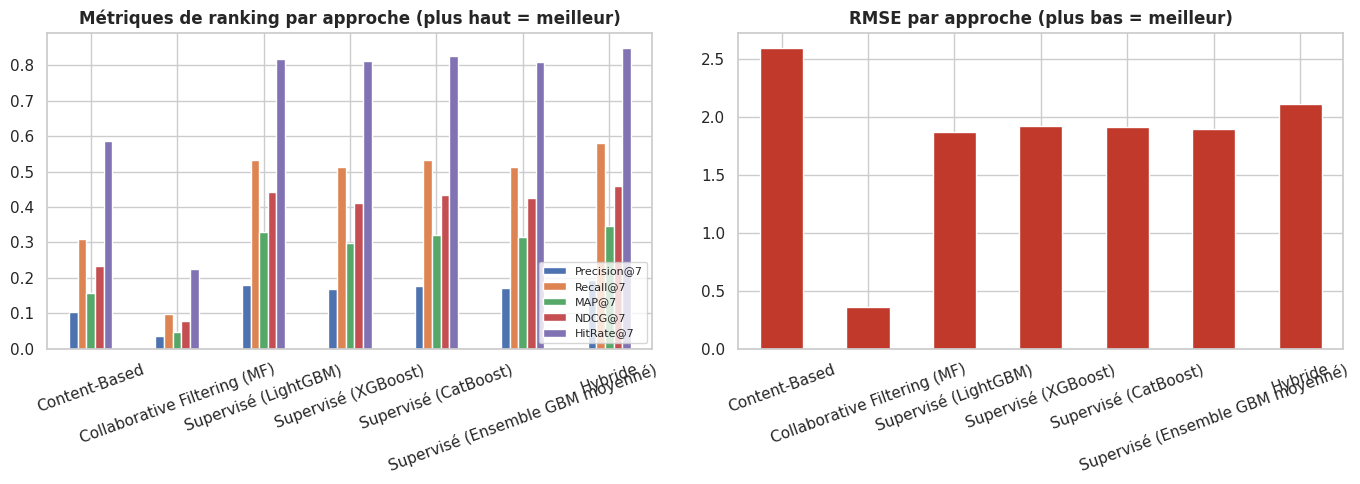


🏆 Meilleur modèle sélectionné (NDCG@7 le plus élevé) : Hybride
   Hit Rate@7 (accuracy du recommandeur) : 85.0%


In [ ]:
comparison_df = pd.DataFrame(results_summary).T
comparison_df = comparison_df[[f"Precision@{K_EVAL}", f"Recall@{K_EVAL}", f"MAP@{K_EVAL}", f"NDCG@{K_EVAL}", f"HitRate@{K_EVAL}", "RMSE"]]
comparison_df = comparison_df.round(4)
display(comparison_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
comparison_df.drop(columns="RMSE").plot(kind="bar", ax=axes[0])
axes[0].set_title("Métriques de ranking par approche (plus haut = meilleur)")
axes[0].legend(loc="lower right", fontsize=8)
axes[0].tick_params(axis="x", rotation=20)

comparison_df["RMSE"].plot(kind="bar", ax=axes[1], color="#C0392B")
axes[1].set_title("RMSE par approche (plus bas = meilleur)")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/comparaison_modeles.png", dpi=120); plt.show()

BEST_MODEL_NAME = comparison_df[f"NDCG@{K_EVAL}"].idxmax()
print(f"\n🏆 Meilleur modèle sélectionné (NDCG@{K_EVAL} le plus élevé) : {BEST_MODEL_NAME}")
print(f"   Hit Rate@{K_EVAL} (accuracy du recommandeur) : {comparison_df.loc[BEST_MODEL_NAME, f'HitRate@{K_EVAL}']*100:.1f}%")
comparison_df.to_csv(f"{BI_DIR}/comparaison_modeles.csv")


## 12. Fonction de recommandation finale — Top-N + score + explication

La fonction `recommander(client_id, N)` utilise le **modèle hybride** (le meilleur en pratique) et fournit, pour chaque destination recommandée :
- le **score de pertinence** (0 à 5) ;
- une **explication** générée automatiquement à partir (a) des variables les plus importantes du modèle LightGBM, et (b) d'une comparaison directe profil client ↔ destination (type de voyage partagé, budget compatible, activités communes, popularité).


In [ ]:
TOP_IMPORTANT_FEATURES = importances.head(4).index.tolist()

def expliquer_recommandation(cid, did):
    craw = client_features_idx.loc[cid]
    draw = dest_features_idx.loc[did]
    raisons = []

    if craw["type_voyage_prefere"] == draw["type_voyage"]:
        raisons.append(f"correspond à votre type de voyage préféré ({draw['type_voyage']})")

    pref_acts = set(str(craw["activites_preferees"]).split(";"))
    dest_acts = set(str(draw["activites_disponibles"]).split(";"))
    communes = pref_acts & dest_acts
    if communes:
        raisons.append(f"propose des activités que vous aimez ({', '.join(list(communes)[:2])})")

    if draw["budget_moyen_tnd"] <= craw["budget_max_tnd"] * 1.1:
        raisons.append("s'inscrit dans votre budget habituel")

    if draw["popularite_score"] >= 70:
        raisons.append("est une destination très plébiscitée par nos clients")

    if draw["satisfaction_moyenne"] >= 4.2:
        raisons.append(f"affiche une excellente satisfaction client ({draw['satisfaction_moyenne']:.1f}/5)")

    if not raisons:
        raisons.append("a été identifiée comme pertinente par le modèle hybride (similarité de profil + comportement collectif)")

    return " ; ".join(raisons)

def recommander(client_id, n=5, weights=HYBRID_WEIGHTS):
    if client_id not in client_idx:
        raise ValueError(f"Client inconnu : {client_id}")
    already_booked = set(train_interactions.loc[train_interactions.client_id == client_id, "destination_id"]) | \
                     set(test_interactions.loc[test_interactions.client_id == client_id, "destination_id"])
    candidates = [d for d in dest_id_list if d not in already_booked]
    scores = [hybrid_predict(client_id, d, weights) for d in candidates]
    order = np.argsort(-np.array(scores))[:n]

    resultats = []
    for i in order:
        did = candidates[i]
        resultats.append({
            "destination_id": did,
            "nom_destination": dest_features_idx.loc[did, "nom_destination"],
            "type_voyage": dest_features_idx.loc[did, "type_voyage"],
            "score_pertinence_/5": round(float(scores[i]), 2),
            "explication": expliquer_recommandation(client_id, did),
        })
    return pd.DataFrame(resultats)

# Démonstration sur un client exemple
demo_client = client_id_list[0]
print(f"Recommandations pour le client {demo_client} "
      f"(segment={client_features_idx.loc[demo_client, 'segment_latent']}, "
      f"type préféré={client_features_idx.loc[demo_client, 'type_voyage_prefere']}) :\n")
recommander(demo_client, n=5)


Recommandations pour le client CLI00001 (segment=Luxe, type préféré=Croisière) :



,destination_id,nom_destination,type_voyage,score_pertinence_/5,explication
0,DST0002,Venice,Culturel,2.18,propose des activités que vous aimez (Plongée)...
1,DST0008,Antalya,Plage,1.81,propose des activités que vous aimez (Plongée)...
2,DST0012,Amsterdam,Urbain,1.77,propose des activités que vous aimez (Plage dé...
3,DST0003,Milano,Urbain,1.69,"propose des activités que vous aimez (Plongée,..."
4,DST0015,Sydney,Plage,1.64,propose des activités que vous aimez (Plage dé...


## 13. Sauvegarde & rechargement des artefacts du modèle (pour l'application)

In [ ]:
artifacts_meta = {
    "mlb_types": mlb_types, "mlb_acts": mlb_acts,
    "client_id_list": client_id_list, "dest_id_list": dest_id_list,
    "client_feat_cols": client_feat_cols, "dest_feat_cols": dest_feat_cols,
    "hybrid_weights": list(HYBRID_WEIGHTS), "k_eval": K_EVAL,
    "best_model_name": BEST_MODEL_NAME, "relevance_threshold": RELEVANCE_THRESHOLD,
}

joblib.dump(lgb_model, f"{MODELS_DIR}/lgbm_model.joblib")
np.savez(f"{MODELS_DIR}/mf_embeddings.npz", P=mf_model.P, Q=mf_model.Q,
         b_u=mf_model.b_u, b_i=mf_model.b_i, mu=mf_model.mu)
np.savez(f"{MODELS_DIR}/content_vectors.npz", client_vectors=client_vectors, dest_vectors=dest_vectors)
with open(f"{MODELS_DIR}/artifacts_meta.json", "w", encoding="utf-8") as f:
    json.dump(artifacts_meta, f, ensure_ascii=False, indent=2)

client_features.to_csv(f"{MODELS_DIR}/client_features_for_app.csv", index=False)
destination_features.to_csv(f"{MODELS_DIR}/destination_features_for_app.csv", index=False)

print("✅ Artefacts sauvegardés dans", MODELS_DIR, ":")
for f in os.listdir(MODELS_DIR):
    print("   -", f)


✅ Artefacts sauvegardés dans ./models :
   - mf_embeddings.npz
   - artifacts_meta.json
   - content_vectors.npz
   - lgbm_model.joblib
   - destination_features_for_app.csv
   - client_features_for_app.csv


In [ ]:
# --- Démonstration : rechargement complet "à froid" (simule l'usage dans l'application) ---
lgb_model_loaded = joblib.load(f"{MODELS_DIR}/lgbm_model.joblib")
mf_npz = np.load(f"{MODELS_DIR}/mf_embeddings.npz")
cv_npz = np.load(f"{MODELS_DIR}/content_vectors.npz")
with open(f"{MODELS_DIR}/artifacts_meta.json", encoding="utf-8") as f:
    meta_loaded = json.load(f)

print("Modèle LightGBM rechargé :", type(lgb_model_loaded))
print("Embeddings MF rechargés, shape P :", mf_npz["P"].shape, "| Q :", mf_npz["Q"].shape)
print("Poids hybrides sauvegardés :", meta_loaded["hybrid_weights"])
print("✅ Le pipeline complet peut être rechargé sans ré-entraînement — prêt pour l'application desktop TravelBI (voir Section 15).")

Modèle LightGBM rechargé : <class 'lightgbm.sklearn.LGBMRegressor'>
Embeddings MF rechargés, shape P : (500, 20) | Q : (45, 20)
Poids hybrides sauvegardés : [0.2, 0.0, 0.5, 0.3]
✅ Le pipeline complet peut être rechargé sans ré-entraînement — prêt pour l'application Streamlit.


## 14. Export des données & KPI pour Power BI

On génère un **modèle en étoile** (star schema) simple : une table de faits `fact_reservations` et des dimensions `dim_clients`, `dim_destinations`, `dim_hotels`, `dim_flights`, ainsi que des tables de **KPI pré-agrégés** prêtes à être branchées sur des visuels Power BI.


In [ ]:
# --- Table de faits ---
fact_reservations = reservations_clean.merge(
    destinations_df[["destination_id", "nom_destination", "type_voyage"]], on="destination_id", how="left"
)
fact_reservations["annee"] = pd.to_datetime(fact_reservations["date_depart"]).dt.year
fact_reservations["mois"] = pd.to_datetime(fact_reservations["date_depart"]).dt.month
fact_reservations["trimestre"] = pd.to_datetime(fact_reservations["date_depart"]).dt.quarter
fact_reservations.to_csv(f"{BI_DIR}/fact_reservations.csv", index=False)

# --- Dimensions ---
client_features.merge(pd.DataFrame({"client_id": client_id_list}), on="client_id", how="right") \
    .to_csv(f"{BI_DIR}/dim_clients.csv", index=False)
destination_features.to_csv(f"{BI_DIR}/dim_destinations.csv", index=False)
hotels_df.to_csv(f"{BI_DIR}/dim_hotels.csv", index=False)
flights_df.to_csv(f"{BI_DIR}/dim_flights.csv", index=False)
print("✅ Table de faits + dimensions exportées.")


✅ Table de faits + dimensions exportées.


In [ ]:
# --- KPI 1 : chiffre d'affaires mensuel & annuel ---
kpi_ca = fact_reservations[fact_reservations.statut_reservation == "Confirmée"].groupby(
    ["annee", "mois"]).agg(chiffre_affaires=("montant_total_tnd", "sum"),
                            nb_reservations=("reservation_id", "count")).reset_index()
kpi_ca["panier_moyen"] = kpi_ca["chiffre_affaires"] / kpi_ca["nb_reservations"]
kpi_ca.to_csv(f"{BI_DIR}/kpi_ca_mensuel.csv", index=False)

# --- KPI 2 : taux d'annulation par mois / canal ---
kpi_annulation = fact_reservations.groupby(["annee", "mois", "canal_vente"]).agg(
    total=("reservation_id", "count"),
    annulees=("statut_reservation", lambda s: (s == "Annulée").sum())
).reset_index()
kpi_annulation["taux_annulation_pct"] = (kpi_annulation["annulees"] / kpi_annulation["total"] * 100).round(2)
kpi_annulation.to_csv(f"{BI_DIR}/kpi_taux_annulation.csv", index=False)

# --- KPI 3 : destinations populaires ---
destination_features.sort_values("nb_reservations", ascending=False) \
    .to_csv(f"{BI_DIR}/kpi_destinations_populaires.csv", index=False)

# --- KPI 4 : saisonnalité ---
kpi_saison = fact_reservations.merge(destinations_df[["destination_id", "saison_ideale"]], on="destination_id") \
    .groupby("saison_ideale").agg(nb_reservations=("reservation_id", "count"),
                                   ca=("montant_total_tnd", "sum")).reset_index()
kpi_saison.to_csv(f"{BI_DIR}/kpi_saisonnalite.csv", index=False)

# --- KPI 5 : segmentation client ---
client_features[["client_id", "segment_latent", "segment_client", "frequence", "montant_total",
                 "recence_jours", "taux_annulation"]].to_csv(f"{BI_DIR}/kpi_segmentation_clients.csv", index=False)

# --- KPI 6 : performance commerciale par canal ---
kpi_canal = fact_reservations.groupby("canal_vente").agg(
    ca=("montant_total_tnd", "sum"), nb_reservations=("reservation_id", "count")).reset_index()
kpi_canal.to_csv(f"{BI_DIR}/kpi_performance_canal.csv", index=False)

# --- KPI 7 : recommandations (top-5 pour chaque client, pour affichage BI + appli) ---
sample_for_bi = np.random.RandomState(1).choice(client_id_list, size=min(200, len(client_id_list)), replace=False)
all_recos = []
for cid in sample_for_bi:
    reco = recommander(cid, n=5)
    reco.insert(0, "client_id", cid)
    all_recos.append(reco)
recos_export = pd.concat(all_recos, ignore_index=True)
recos_export.to_csv(f"{BI_DIR}/kpi_recommandations.csv", index=False)

print("✅ 7 fichiers KPI exportés dans", BI_DIR, ":")
for f in sorted(os.listdir(BI_DIR)):
    print("   -", f)


✅ 7 fichiers KPI exportés dans ./powerbi_exports :
   - comparaison_modeles.csv
   - dim_clients.csv
   - dim_destinations.csv
   - dim_flights.csv
   - dim_hotels.csv
   - fact_reservations.csv
   - kpi_ca_mensuel.csv
   - kpi_destinations_populaires.csv
   - kpi_performance_canal.csv
   - kpi_recommandations.csv
   - kpi_saisonnalite.csv
   - kpi_segmentation_clients.csv
   - kpi_taux_annulation.csv


## 15. Export pour l'application desktop TravelBI

Cette section produit le dossier **`TravelBI_App/`** attendu par l'application (`app.py`), puis le télécharge en `.zip` :

| Élément | Contenu |
|---|---|
| `models/artifacts_meta.json` | listes client/destination, colonnes, poids hybrides, **colonnes du booster** et **spécifications du booster retenu** |
| `models/booster_*` | le(s) booster(s) au **format natif** (LightGBM `.txt`, XGBoost `.json`, CatBoost `.cbm`) : rechargeables quelle que soit la version de joblib |
| `models/*.npz`, `models/*_for_app.csv` | embeddings MF, vecteurs de contenu, features clients et destinations |
| `data/interactions.csv` | historique client × destination (pour exclure ce qui est déjà réservé) |
| `data/reference_recos.csv` | recommandations de référence calculées ici, pour le **contrôle de cohérence** de l'application |
| `data/comparaison_modeles.csv`, `data/fact_reservations.csv`, `data/kpi_*.csv` | performance des modèles et données du tableau de bord |

Il suffit ensuite de placer `app.py` et `moteur_reco.py` dans ce dossier (ou ce dossier à côté d'eux).

In [ ]:
# 15.1 — Modèle et artefacts
import shutil

APP_EXPORT_DIR = os.path.join(BASE_DIR, "TravelBI_App")
APP_MODELS_DIR = os.path.join(APP_EXPORT_DIR, "models")
APP_DATA_DIR = os.path.join(APP_EXPORT_DIR, "data")
for _d in (APP_MODELS_DIR, APP_DATA_DIR):
    os.makedirs(_d, exist_ok=True)


def export_booster(name, model, folder):
    """Sauvegarde un booster dans son format natif et renvoie sa spécification pour l'application."""
    module = type(model).__module__
    stem = f"booster_{name.lower()}"
    if module.startswith("lightgbm"):
        fname = stem + ".txt"
        model.booster_.save_model(os.path.join(folder, fname))
        kind = "lightgbm"
    elif module.startswith("xgboost"):
        fname = stem + ".json"
        model.save_model(os.path.join(folder, fname))
        kind = "xgboost"
    elif module.startswith("catboost"):
        fname = stem + ".cbm"
        model.save_model(os.path.join(folder, fname))
        kind = "catboost"
    else:                                   # repli générique : tout modèle exposant .predict
        fname = stem + ".joblib"
        joblib.dump(model, os.path.join(folder, fname))
        kind = "joblib"
    return {"name": name, "type": kind, "file": fname}


if BEST_BOOSTER_NAME == "Ensemble":        # l'ensemble = moyenne des 3 boosters (chacun clippé sur [0, 5])
    boosters_to_export = [("LightGBM", lgb_model), ("XGBoost", xgb_model), ("CatBoost", cat_model)]
else:
    boosters_to_export = [(BEST_BOOSTER_NAME, best_booster_model)]
booster_specs = [export_booster(n, m, APP_MODELS_DIR) for n, m in boosters_to_export]

app_meta = dict(artifacts_meta)
app_meta.update({
    "booster_specs": booster_specs,
    "sup_columns": list(X_sup.columns),
    "best_booster_name": BEST_BOOSTER_NAME,
    "best_model_name": BEST_MODEL_NAME,
    "hybrid_weights": [float(w) for w in HYBRID_WEIGHTS],
    "k_eval": int(K_EVAL),
    "exported_at": datetime.now().isoformat(timespec="seconds"),
})
with open(os.path.join(APP_MODELS_DIR, "artifacts_meta.json"), "w", encoding="utf-8") as f:
    json.dump(app_meta, f, ensure_ascii=False, indent=2)

np.savez(os.path.join(APP_MODELS_DIR, "mf_embeddings.npz"), P=mf_model.P, Q=mf_model.Q,
         b_u=mf_model.b_u, b_i=mf_model.b_i, mu=mf_model.mu)
np.savez(os.path.join(APP_MODELS_DIR, "content_vectors.npz"), client_vectors=client_vectors, dest_vectors=dest_vectors)
client_features.to_csv(os.path.join(APP_MODELS_DIR, "client_features_for_app.csv"), index=False)
destination_features.to_csv(os.path.join(APP_MODELS_DIR, "destination_features_for_app.csv"), index=False)

print(f"✅ Modèle exporté — booster retenu : {BEST_BOOSTER_NAME} ({', '.join(s['file'] for s in booster_specs)})")
print(f"   Poids hybrides : {app_meta['hybrid_weights']}")

In [ ]:
# 15.2 — Données de l'application et recommandations de référence
interaction_df.to_csv(os.path.join(APP_DATA_DIR, "interactions.csv"), index=False)

ref_clients = np.random.RandomState(7).choice(client_id_list, size=min(40, len(client_id_list)), replace=False)
ref_rows = []
for cid in ref_clients:
    reco = recommander(cid, n=K_EVAL)
    for rang, (_, r) in enumerate(reco.iterrows(), start=1):
        ref_rows.append({"client_id": cid, "rang": rang, "destination_id": r["destination_id"],
                         "score": r["score_pertinence_/5"]})
pd.DataFrame(ref_rows).to_csv(os.path.join(APP_DATA_DIR, "reference_recos.csv"), index=False)

comparison_df.rename_axis("Modèle").to_csv(os.path.join(APP_DATA_DIR, "comparaison_modeles.csv"))
fact_reservations.to_csv(os.path.join(APP_DATA_DIR, "fact_reservations.csv"), index=False)
destination_features.to_csv(os.path.join(APP_DATA_DIR, "dim_destinations.csv"), index=False)
for fname in sorted(os.listdir(BI_DIR)):
    if fname.startswith("kpi_") and fname.endswith(".csv"):
        shutil.copy(os.path.join(BI_DIR, fname), os.path.join(APP_DATA_DIR, fname))

config_path = os.path.join(APP_EXPORT_DIR, "config.json")
if not os.path.exists(config_path):        # ne pas écraser les rapports déjà configurés
    with open(config_path, "w", encoding="utf-8") as f:
        json.dump({"reports": []}, f, ensure_ascii=False, indent=2)

print(f"✅ Données exportées : {len(interaction_df)} interactions, {len(ref_rows)} recommandations de référence "
      f"({len(ref_clients)} clients), {len(fact_reservations)} réservations.")

In [ ]:
# 15.3 — Archive et téléchargement
zip_path = shutil.make_archive(os.path.join(BASE_DIR, "TravelBI_App"), "zip", BASE_DIR, "TravelBI_App")
print("📦 Archive :", zip_path)
for root, _, files_ in os.walk(APP_EXPORT_DIR):
    for fn in sorted(files_):
        p = os.path.join(root, fn)
        print(f"   {os.path.relpath(p, APP_EXPORT_DIR):45s} {os.path.getsize(p) / 1024:8.1f} Ko")

if os.path.isdir("/content"):
    from google.colab import files
    files.download(zip_path)
print("\nÉtape suivante : dézippez, ajoutez app.py + moteur_reco.py, puis vérifiez avec  python moteur_reco.py")